# Aufgabe: Leben ohne Sauerstoff

*E. coli* lebt in unserem Darm, wo es kaum Sauerstoff gibt. Kann es dort wachsen? Und was ändert sich?

Führe die ersten beiden Zellen aus, um alles vorzubereiten.

In [1]:
setLanguage('de')   % Sprache der Ausgaben

Sprache: Deutsch


In [2]:
model = loadEcoli();

Modell geladen: E.-coli-Kernmodell mit 95 Reaktionen, 72 Metaboliten und 137 Genen.


## Mit Sauerstoff

`setMedium(model, glucose, oxygen)` legt fest, wie viel Glukose und Sauerstoff die Zellen höchstens aufnehmen dürfen. 1000 bedeutet „so viel sie wollen“.

In [3]:
model_air = setMedium(model, 10, 1000);
[growth_air, solution_air] = showGrowth(model_air);

Nahrung: Glukose-Aufnahme bis 10, Sauerstoff-Aufnahme bis 1000 (mmol pro Gramm pro Stunde).
Wachstumsrate: 0.874 pro Stunde (die Zellen verdoppeln sich alle 48 Minuten).


## Ohne Sauerstoff

Jetzt nimm den Sauerstoff weg. Ersetze `___` durch die richtige Zahl.

In [4]:
model_no_air = setMedium(model, 10, 0);
[growth_no_air, solution_no_air] = showGrowth(model_no_air);

Nahrung: Glukose-Aufnahme bis 10, Sauerstoff-Aufnahme bis 0 (mmol pro Gramm pro Stunde).
Wachstumsrate: 0.212 pro Stunde (die Zellen verdoppeln sich alle 196 Minuten).


**Frage 1:** Kann *E. coli* ohne Sauerstoff wachsen? Wie viel Mal langsamer ist es? *(Tipp: Du kannst in einer Code-Zelle rechnen, z. B. `growth_air / growth_no_air`.)*

In [5]:
growth_air / growth_no_air

ans = 4.1288


✅ **Antwort:** Ja, es wächst noch, aber etwa **4-mal langsamer**: 0,212 statt 0,874 pro Stunde. Es verdoppelt sich alle 196 Minuten statt alle 48 Minuten.

## Was kommt ohne Sauerstoff heraus?

In [6]:
showExchange(model_no_air, solution_no_air)

Die Zellen NEHMEN AUF:
  Glukose (Zucker)                10.00
  Wasser                           7.12
  Ammonium (Stickstoff)            1.15
  Phosphat                         0.78
  Kohlendioxid (CO2)               0.38
Die Zellen GEBEN AB:
  H+ (Säure)                      30.55
  Formiat (Ameisensäure)          17.80
  Acetat (Essigsäure)              8.50
  Ethanol (Alkohol)                8.28


**Frage 2:** Welche Stoffe gibt *E. coli* jetzt ab, die es mit Sauerstoff nicht abgegeben hat? Kennst du einige davon aus dem Alltag?

✅ **Antwort:** **Formiat** (Ameisensäure, bekannt von Ameisenbissen), **Acetat** (die Säure im Essig) und **Ethanol** (der Alkohol in Bier und Wein). Das nennt man **Gärung** (Fermentation). Hefe macht das Gleiche, wenn Brotteig aufgeht und wenn Bier gebraut wird, und deine Muskeln bilden Milchsäure, wenn ihnen der Sauerstoff ausgeht.

**Warum?** Mit Sauerstoff kann die Zelle Glukose vollständig zu CO₂ „verbrennen“ und bekommt dabei viel Energie (ATP). Ohne Sauerstoff kann sie Glukose nur zur Hälfte abbauen. Sie bekommt viel weniger Energie, und die halb genutzten Moleküle werden als Abfall abgegeben. Weniger Energie heißt langsameres Wachstum.

## Wie viel Sauerstoff ist genug?

Die Zelle unten berechnet die Wachstumsrate für viele verschiedene Sauerstoffmengen und zeichnet ein Diagramm. Führe sie einfach aus.

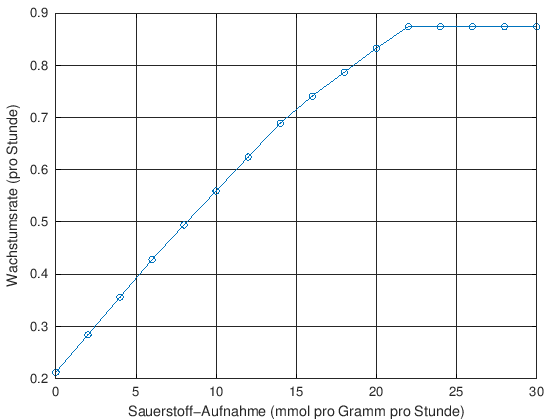

In [7]:
oxygen = 0:2:30;                      % 0, 2, 4, ... 30
growth = zeros(size(oxygen));
for i = 1:numel(oxygen)
  m = changeRxnBounds(model, 'EX_o2_e', -oxygen(i), 'l');   % so viel Sauerstoff erlauben
  s = optimizeCbModel(m);                                     % FBA ausführen
  growth(i) = s.f;                                            % Wachstumsrate merken
end
plot(oxygen, growth, 'o-', 'linewidth', 2)
xlabel('Sauerstoff-Aufnahme (mmol pro Gramm pro Stunde)')
ylabel('Wachstumsrate (pro Stunde)')
grid on

**Frage 3:** Beschreibe das Diagramm. Ab welcher Sauerstoffmenge hilft mehr Sauerstoff nicht mehr? Warum wird die Linie flach?

✅ **Antwort:** Das Wachstum steigt mit dem Sauerstoff gleichmäßig an und wird bei etwa **22** Einheiten flach. Ab dann ist die Glukose die Grenze: Die Zelle verbrennt schon alle 10 Einheiten Zucker, die sie aufnehmen kann, und für mehr Sauerstoff gibt es nichts mehr zu verbrennen.

**Fertig!** Weiter geht es mit `03_exercise_food.ipynb`.

<small>Modell: *E.-coli*-Kernmodell aus BiGG Models (Orth et al. 2010; King et al. 2016). Software: COBRA Toolbox (Heirendt et al. 2019) in GNU Octave. Vollständige Quellen am Ende von `01_tutorial_fba.ipynb`.</small>